# Building the Knowledge Graph

This notebook is dedicated to constructing the Knowledge Graph (KG) for this project. 

To build the graph, we use the `rdflib` library together with the provided master datasets (`components.csv`, `causes.csv`, `symptoms.csv`, `relations.csv`, and `procedures.csv` files), exported via the `pandas` library. Additional libraries, including `matplotlib` and `networkx`, are used to support graphical representation of the resulting graph structure.

In [1]:
from rdflib import Graph, Namespace, URIRef, Literal, RDF, RDFS, XSD, OWL
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
EX = Namespace("http://example.org/cnc#")

def create_uri(string):
    safe = (
        str(string)
        .strip()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("/", "_")
    )
    return EX[safe]

g = Graph()

g.bind("ex", EX)
g.bind("rdf", RDF)
g.bind("rdfs", RDFS)
g.bind("xsd", XSD)
g.bind("owl", OWL)

# components.csv
data = pd.read_csv("../data/raw/components.csv")

g.add((EX.Component, RDF.type, OWL.Class))

g.add((EX.hasID, RDF.type, OWL.DatatypeProperty))
g.add((EX.hasID, RDFS.domain, EX.Component))
g.add((EX.hasID, RDFS.range, XSD.string))

g.add((EX.hasName, RDF.type, OWL.DatatypeProperty))
g.add((EX.hasName, RDFS.domain, EX.Component))
g.add((EX.hasName, RDFS.range, XSD.string))

g.add((EX.function, RDF.type, OWL.DatatypeProperty))
g.add((EX.function, RDFS.domain, EX.Component))
g.add((EX.function, RDFS.range, XSD.string))

g.add((EX.partOf, RDF.type, OWL.ObjectProperty))
g.add((EX.partOf, RDFS.domain, EX.Component))
g.add((EX.partOf, RDFS.range, EX.Component))

for _, row in data.iterrows():
    id = row['component_id']
    name = row['name']
    func = row['function']

    uri = create_uri(name)
    g.add((uri, RDF.type, EX.Component))

    g.add((uri, EX.hasID, Literal(id)))
    g.add((uri, EX.hasName, Literal(name)))
    g.add((uri, EX.function, Literal(func)))

    if not pd.isna(row['parent_component']):
        parent = row['parent_component']
        parent_uri = create_uri(data[data['component_id'] == parent]['name'].values[0])
        g.add((uri, EX.partOf, parent_uri))

# causes.csv
data = pd.read_csv("../data/raw/causes.csv")

g.add((EX.Cause, RDF.type, OWL.Class))

g.add((EX.hasID, RDF.type, OWL.DatatypeProperty))
g.add((EX.hasID, RDFS.domain, EX.Cause))
g.add((EX.hasID, RDFS.range, XSD.string))

g.add((EX.hasName, RDF.type, OWL.DatatypeProperty))
g.add((EX.hasName, RDFS.domain, EX.Cause))
g.add((EX.hasName, RDFS.range, XSD.string))

for _, row in data.iterrows():
    id = row['cause_id']
    name = row['name']

    uri = create_uri(name)
    g.add((uri, RDF.type, EX.Cause))

    g.add((uri, EX.hasID, Literal(id)))
    g.add((uri, EX.hasName, Literal(name)))

# symptoms.csv
data = pd.read_csv("../data/raw/symptoms.csv")

g.add((EX.Symptom, RDF.type, OWL.Class))

g.add((EX.hasID, RDF.type, OWL.DatatypeProperty))
g.add((EX.hasID, RDFS.domain, EX.Symptom))
g.add((EX.hasID, RDFS.range, XSD.string))

g.add((EX.hasName, RDF.type, OWL.DatatypeProperty))
g.add((EX.hasName, RDFS.domain, EX.Symptom))
g.add((EX.hasName, RDFS.range, XSD.string))

for _, row in data.iterrows():
    id = row['symptom_id']
    name = row['name']

    uri = create_uri(name)
    g.add((uri, RDF.type, EX.Symptom))
    g.add((uri, EX.hasID, Literal(id)))
    g.add((uri, EX.hasName, Literal(name)))

# relations.csv
data = pd.read_csv("../data/raw/relations.csv")

# there are only 2 types of relations, add more it necessary
g.add((EX.causesSymptom, RDF.type, OWL.ObjectProperty))
g.add((EX.causesSymptom, RDFS.domain, EX.Cause))
g.add((EX.causesSymptom, RDFS.range, EX.Symptom))

g.add((EX.affectsComponent, RDF.type, OWL.ObjectProperty))
g.add((EX.affectsComponent, RDFS.domain, EX.Cause))
g.add((EX.affectsComponent, RDFS.range, EX.Component))

for _, row in data.iterrows():
    subj = create_uri(row['subj'])
    pred = create_uri(row['pred'])
    obj = create_uri(row['obj'])

    g.add((subj, pred, obj))

# procedures.csv
data = pd.read_csv("../data/raw/procedures.csv")

g.add((EX.Procedure, RDF.type, OWL.Class))

g.add((EX.hasID, RDF.type, OWL.DatatypeProperty))
g.add((EX.hasID, RDFS.domain, EX.Procedure))
g.add((EX.hasID, RDFS.range, XSD.string))

g.add((EX.hasName, RDF.type, OWL.DatatypeProperty))
g.add((EX.hasName, RDFS.domain, EX.Procedure))
g.add((EX.hasName, RDFS.range, XSD.string))

g.add((EX.targetsComponent, RDF.type, OWL.ObjectProperty))
g.add((EX.targetsComponent, RDFS.domain, EX.Procedure))
g.add((EX.targetsComponent, RDFS.range, EX.Component))

g.add((EX.mitigatesCause, RDF.type, OWL.ObjectProperty))
g.add((EX.mitigatesCause, RDFS.domain, EX.Procedure))
g.add((EX.mitigatesCause, RDFS.range, EX.Cause))

g.add((EX.effortHours, RDF.type, OWL.DatatypeProperty))
g.add((EX.effortHours, RDFS.domain, EX.Procedure))
g.add((EX.effortHours, RDFS.range, XSD.float))

g.add((EX.sparePartsCostEur, RDF.type, OWL.DatatypeProperty))
g.add((EX.sparePartsCostEur, RDFS.domain, EX.Procedure))
g.add((EX.sparePartsCostEur, RDFS.range, XSD.float))

g.add((EX.riskRating, RDF.type, OWL.DatatypeProperty))
g.add((EX.riskRating, RDFS.domain, EX.Procedure))
g.add((EX.riskRating, RDFS.range, XSD.int))

for _, row in data.iterrows():
    id = row['proc_id']
    name = row['name']
    target = row['targets_component']
    cause = row['mitigates_cause']
    effort_h = row['effort_h']
    spare_parts_cost = row['spare_parts_cost_eur']
    risk = row['risk_rating']

    uri = create_uri(name)

    g.add((uri, RDF.type, EX.Procedure))
    g.add((uri, EX.hasID, Literal(id)))
    g.add((uri, EX.hasName, Literal(name)))

    target_uri = create_uri(target)
    g.add((uri, EX.targetsComponent, target_uri))

    cause_uri = create_uri(cause)
    g.add((uri, EX.mitigatesCause, cause_uri))

    g.add((uri, EX.effortHours, Literal(effort_h, datatype=XSD.float)))
    g.add((uri, EX.sparePartsCostEur, Literal(spare_parts_cost, datatype=XSD.float)))
    g.add((uri, EX.riskRating, Literal(risk, datatype=XSD.integer)))

# serialize and store graph
g.serialize(destination='../data/knowledgeGraph/knowledgeGraph.ttl', format='turtle')
print(end='')


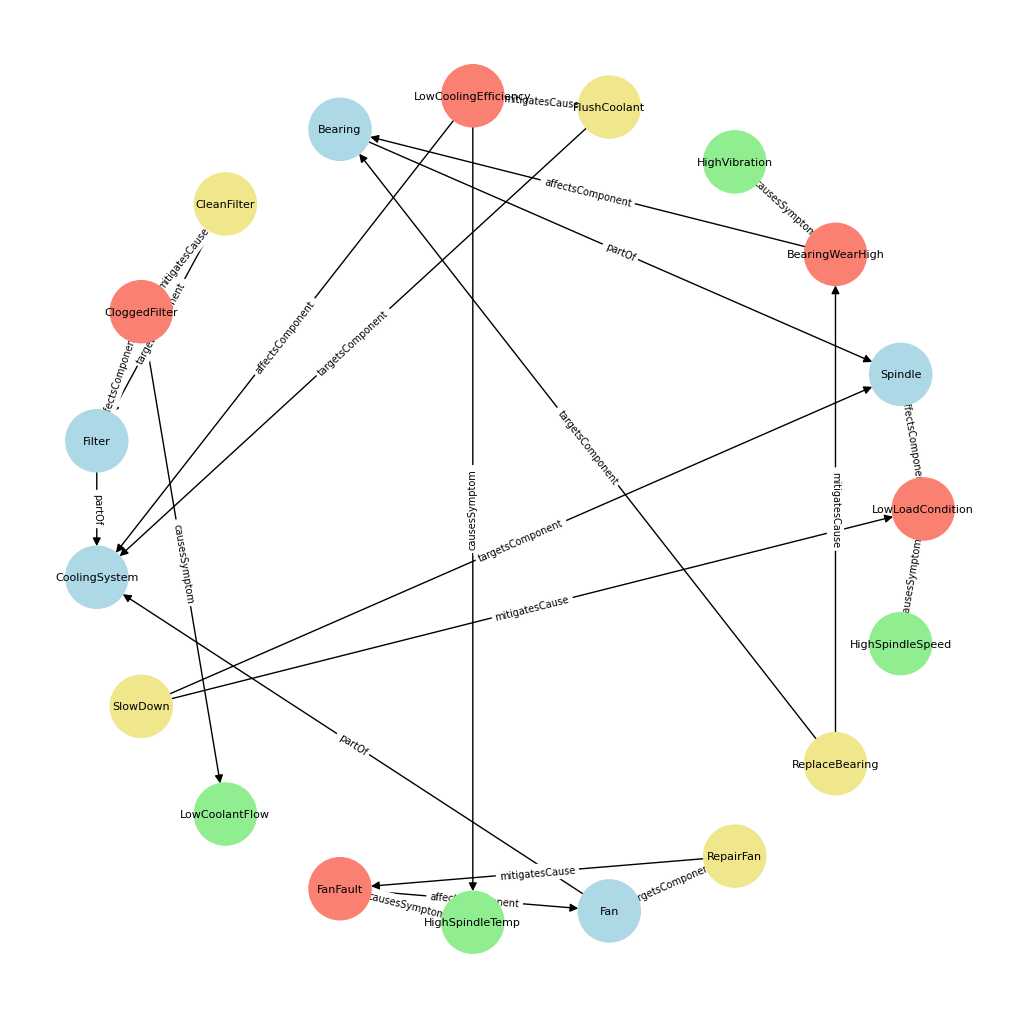

In [3]:
def get_type(graph, node):
    for t in graph.objects(node, RDF.type):
        if t == EX.Component:
            return 'Component'
        elif t == EX.Cause:
            return 'Cause'
        elif t == EX.Symptom:
            return 'Symptom'
        elif t == EX.Procedure:
            return 'Procedure'
        else:
            return 'Other'

graph = nx.DiGraph()

predicates = {
    EX.causesSymptom: 'causesSymptom',
    EX.affectsComponent: 'affectsComponent',
    EX.mitigatesCause: 'mitigatesCause',
    EX.targetsComponent: 'targetsComponent',
    EX.partOf: 'partOf'
}

for subj, pred, obj in g:
    if pred in predicates:
        graph.add_node(subj)
        graph.add_node(obj)
        graph.add_edge(subj, obj, label=predicates[pred])

pos = nx.circular_layout(graph)

colors = []
for node in graph.nodes():
    t = get_type(g, node)
    if t == 'Component':
        colors.append('lightblue')
    elif t == "Cause":
        colors.append("salmon")
    elif t == "Symptom":
        colors.append("lightgreen")
    elif t == "Procedure":
        colors.append("khaki")
    else:
        colors.append("lightgrey")

labels = {node: str(node).split('#')[-1] for node in graph.nodes()}

plt.figure(figsize=(10, 10))

nx.draw(
    graph,
    pos,
    with_labels=True,
    labels=labels,
    node_color=colors,
    node_size=2000,
    font_size=8,
    arrows=True,
    arrowstyle='-|>',
    arrowsize=12
)

edge_labels = nx.get_edge_attributes(graph, "label")
nx.draw_networkx_edge_labels(graph, pos, edge_labels=edge_labels, font_size=7)
plt.show()